We initiate Keras with the PyTorch backend.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras

print("Keras version:", keras.__version__)
print("Backend:", keras.backend.backend())

keras.utils.set_random_seed(42)


Keras version: 3.13.2
Backend: torch


In [2]:
!pip install scikit-learn-intelex ucimlrepo torchinfo



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 29.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 50.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 72.2 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: tbb
    Found existing installation: tbb 2022.3.1
    Uninstalling tbb-2022.3.1:
      Successfully uninstalled tbb-2022.3.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mkl 2025.3.1 requires tbb==2022.*, but you have tbb 2023.2.0 which is incompatible.


We enable the Intel Extensions for Scikit-Learn, which allows speedup for Sklearn operations:

In [3]:
import sys

# Kaggle-specific
sys.path.insert(
    0,
    "/usr/local/lib/python3.13/site-packages",
)

from sklearnex import patch_sklearn

patch_sklearn()

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


# Part A: Comparing Traditional Machine Learning Models

## Step A.1: Load and Analyse Your Dataset

We load the dataset via the UCI ML repository; which already separates features and targets.

In [4]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import json
  
# fetch dataset 
beijing_pm2_5 = fetch_ucirepo(id=381) 
  
# data (as pandas dataframes) 
X = pd.DataFrame(beijing_pm2_5.data.features )
y = pd.DataFrame(beijing_pm2_5.data.targets )
  
# metadata 
print(json.dumps(beijing_pm2_5.metadata, indent = 2)) 
  
# variable information 
print(beijing_pm2_5.variables) 


{
  "uci_id": 381,
  "name": "Beijing PM2.5",
  "repository_url": "https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data",
  "data_url": "https://archive.ics.uci.edu/static/public/381/data.csv",
  "abstract": "This hourly data set contains the PM2.5 data of US Embassy in Beijing. Meanwhile, meteorological data from Beijing Capital International Airport are also included. ",
  "area": "Climate and Environment",
  "tasks": [
    "Regression"
  ],
  "characteristics": [
    "Multivariate",
    "Time-Series"
  ],
  "num_instances": 43824,
  "num_features": 11,
  "feature_types": [
    "Integer",
    "Real"
  ],
  "demographics": [],
  "target_col": [
    "pm2.5"
  ],
  "index_col": [
    "No"
  ],
  "has_missing_values": "yes",
  "missing_values_symbol": "NaN",
  "year_of_dataset_creation": 2015,
  "last_updated": "Sat Mar 16 2024",
  "dataset_doi": "10.24432/C5JS49",
  "creators": [
    "Song Chen"
  ],
  "intro_paper": {
    "ID": 432,
    "type": "NATIVE",
    "title": "Assessing B

## Step A.2: Preprocess Your Data

First, we remove missing values.

In [5]:
X = X.copy()
y = y.copy()

valid = y["pm2.5"].notna()

# the pd.DataFrame is mostly to enforce type for my LSP
X = pd.DataFrame(X.loc[valid].copy())
y = pd.DataFrame(y.loc[valid].copy())

print("Original observations:", len(valid))
print("Valid observations:", valid.sum())
print("Missing targets:", (~valid).sum())

Original observations: 43824
Valid observations: 41757
Missing targets: 2067


We create the features engineered in the EDA. This include dewpoint spread, cyclical time encoding, one-hot encoding the `cbwd` feature,  `log_Iws`, and relative humidity. 

The dataset is already split between features and targets.

In [6]:
import numpy as np

X_engineered = X.copy()

# cyclical time encoding

X_engineered["month_sin"] = np.sin(2 * np.pi * X["month"] / 12)
X_engineered["month_cos"] = np.cos(2 * np.pi * X["month"] / 12)

X_engineered["hour_sin"] = np.sin(2 * np.pi * X["hour"] / 24)
X_engineered["hour_cos"] = np.cos(2 * np.pi * X["hour"] / 24)
X_engineered["log_Iws"] = np.log1p(X["Iws"])
X_engineered["log_Iws"].describe()


b = 17.625
c = 243.04

T = X["TEMP"]
D = X["DEWP"]

X_engineered["RH"] = 100 * np.exp(
    (b * D / (c + D))
    - (b * T / (c + T))
)

X_engineered = pd.get_dummies(
    X_engineered,
    columns=["cbwd"],
    dtype=int
)


X_engineered

,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir,month_sin,month_cos,hour_sin,hour_cos,log_Iws,RH,cbwd_NE,cbwd_NW,cbwd_SE,cbwd_cv
24,2010,1,2,0,-16,-4.0,1020.0,1.79,0,0,5.000000e-01,0.866025,0.000000,1.000000,1.026042,38.784785,0,0,1,0
25,2010,1,2,1,-15,-4.0,1020.0,2.68,0,0,5.000000e-01,0.866025,0.258819,0.965926,1.302913,42.130158,0,0,1,0
26,2010,1,2,2,-11,-5.0,1021.0,3.57,0,0,5.000000e-01,0.866025,0.500000,0.866025,1.519513,62.793843,0,0,1,0
27,2010,1,2,3,-7,-5.0,1022.0,5.36,1,0,5.000000e-01,0.866025,0.707107,0.707107,1.850028,85.857955,0,0,1,0
28,2010,1,2,4,-7,-5.0,1022.0,6.25,2,0,5.000000e-01,0.866025,0.866025,0.500000,1.981001,85.857955,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43819,2014,12,31,19,-23,-2.0,1034.0,231.97,0,0,-2.449294e-16,1.000000,-0.965926,0.258819,5.450910,18.340886,0,1,0,0
43820,2014,12,31,20,-22,-3.0,1034.0,237.78,0,0,-2.449294e-16,1.000000,-0.866025,0.500000,5.475543,21.568601,0,1,0,0
43821,2014,12,31,21,-22,-3.0,1034.0,242.70,0,0,-2.449294e-16,1.000000,-0.707107,0.707107,5.495938,21.568601,0,1,0,0
43822,2014,12,31,22,-22,-4.0,1034.0,246.72,0,0,-2.449294e-16,1.000000,-0.500000,0.866025,5.512299,23.240409,0,1,0,0


## Step A.3: Train Two Traditional ML Models

We create a `results` dictionary to save results.

In [7]:
results = {}

We train the Random Forest Regressor _before_ scaling; as scaling is unnecessary for that model. 

So we create splits first to train Random Forest, then scale later for MLP and LSTM. For simplicity, we use the default hyperparameters for the Random Forest.

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error



X_train, X_test, y_train, y_test = train_test_split(
    X_engineered, y,
    test_size=0.2,
    random_state=42, 
    # shuffle = False
)

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# sklearnex requires this
y_train = y_train.to_numpy().ravel()
y_test = y_test.to_numpy().ravel()

rf.fit(X_train, y_train)

pred = rf.predict(X_test)

rf_results = {
    "RMSE": root_mean_squared_error(y_test, pred),
    "MAE": mean_absolute_error(y_test, pred),
    "R^2": r2_score(y_test, pred),
}

rf_results

{'RMSE': 41.36466180346098, 'MAE': 24.81550287356322, 'R^2': 0.80581826801814}

In [9]:
from sklearn.model_selection import cross_validate


rf_cv_results = cross_validate(
    rf, X_train, y_train, 
    cv = 5, n_jobs = -1, 
    scoring={
        "R2": "r2",
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error"
})

rf_cv_summary = {
    "CV R^2": rf_cv_results["test_R2"].mean(),
    "CV RMSE": -rf_cv_results["test_RMSE"].mean(),
    "CV MAE": -rf_cv_results["test_MAE"].mean()
}

rf_results.update(rf_cv_summary)
results["RF"] = rf_results


rf_cv_summary

{'CV R^2': np.float64(0.7964833258029169),
 'CV RMSE': np.float64(41.29443831344546),
 'CV MAE': np.float64(26.217336177218975)}

Now, we scale the dataset for MLP and LSTM.

In [10]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Separate scalers for features and target
x_scaler = StandardScaler().set_output(transform="pandas")
y_scaler = StandardScaler()

# Chronological split
X_train, X_test, y_train, y_test = train_test_split(
    X_engineered,
    y,
    test_size=0.2,
)

# Scale features
X_train = x_scaler.fit_transform(X_train)
X_test = x_scaler.transform(X_test)

# Scale target
y_train_scaled = y_scaler.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
).ravel()

y_test_scaled = y_scaler.transform(
    np.asarray(y_test).reshape(-1, 1)
).ravel()

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train_scaled.shape}")
print(f"y_test shape: {y_test_scaled.shape}")

X_train shape: (33405, 20)
X_test shape: (8352, 20)
y_train shape: (33405,)
y_test shape: (8352,)


Then we train the MLP model, using the default hyperparameters in the example notebook.

In [11]:
from sklearn.neural_network import MLPRegressor

mlp = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
mlp.fit(X_train, y_train_scaled)

y_pred_scaled = mlp.predict(X_test)

y_pred = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

mlp_results = {
    "RMSE": root_mean_squared_error(y_test, y_pred),
    "MAE": mean_absolute_error(y_test, y_pred),
    "R^2": r2_score(y_test, y_pred),
}


mlp_results

{'RMSE': 48.24710784623302,
 'MAE': 32.55160628908441,
 'R^2': 0.7362317582954959}

MLP CV requires a more complex pipeline:

In [12]:
# Original unscaled data, for CV

from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_engineered,
    y,
    test_size=0.2,
    shuffle=True,
    random_state=42,
)


mlp_cv_model = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(100, 50),
            max_iter=500,
            random_state=42,
        ),
    ),
    transformer=StandardScaler(),
)

mlp_cv_results = cross_validate(
    mlp_cv_model,
    X_train_raw,
    y_train_raw,
    cv=5,
    scoring={
        "R2": "r2",
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error",
    },
    n_jobs=-1,
)

mlp_cv_summary = {
    "CV R^2": mlp_cv_results["test_R2"].mean(),
    "CV RMSE": -mlp_cv_results["test_RMSE"].mean(),
    "CV MAE": -mlp_cv_results["test_MAE"].mean()
}

mlp_results.update(mlp_cv_summary)

results["MLP"] = mlp_results

mlp_cv_summary

{'CV R^2': np.float64(0.720332276538023),
 'CV RMSE': np.float64(48.42500816176842),
 'CV MAE': np.float64(33.1265079835101)}

## Step A.4: Evaluate and Compare Models

We obtain the results for the two models above

In [13]:
results

{'RF': {'RMSE': 41.36466180346098,
  'MAE': 24.81550287356322,
  'R^2': 0.80581826801814,
  'CV R^2': np.float64(0.7964833258029169),
  'CV RMSE': np.float64(41.29443831344546),
  'CV MAE': np.float64(26.217336177218975)},
 'MLP': {'RMSE': 48.24710784623302,
  'MAE': 32.55160628908441,
  'R^2': 0.7362317582954959,
  'CV R^2': np.float64(0.720332276538023),
  'CV RMSE': np.float64(48.42500816176842),
  'CV MAE': np.float64(33.1265079835101)}}

We preview the results:

In [14]:
results_df = pd.DataFrame(results)
results_df.T

,RMSE,MAE,R^2,CV R^2,CV RMSE,CV MAE
RF,41.364662,24.815503,0.805818,0.796483,41.294438,26.217336
MLP,48.247108,32.551606,0.736232,0.720332,48.425008,33.126508


## Step A.5: Visualise Results

<Axes: >

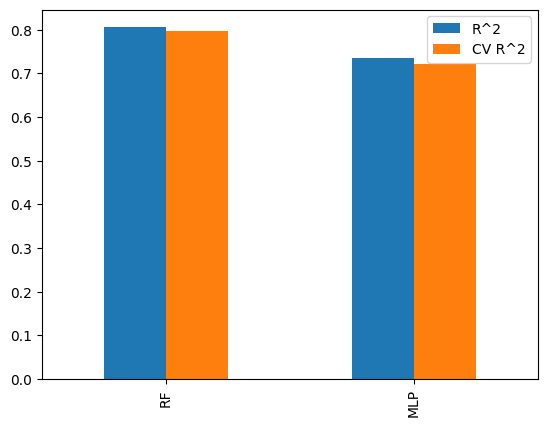

In [15]:
results_df.T[["R^2", "CV R^2"]].plot.bar()

<Axes: >

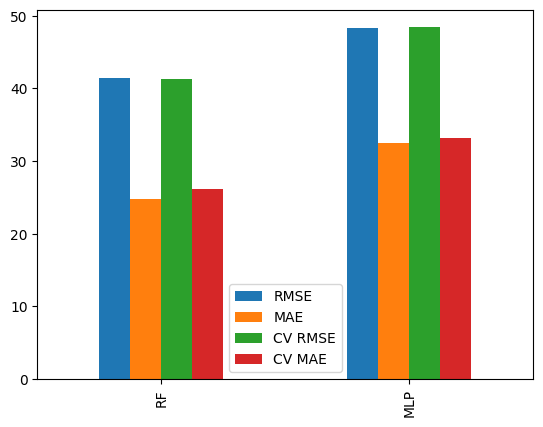

In [16]:
results_df.T[["RMSE", "MAE", "CV RMSE", "CV MAE"]].plot.bar()

# Part B: Deep Learning - LSTM for Regression

## Step B.1: Prepare Sequential Data

We split and scale the data.

In [17]:
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(X_engineered, y,
    test_size=0.2,
    shuffle=False
)

lstm_x_scaler = MinMaxScaler().set_output(transform="pandas")
lstm_y_scaler = MinMaxScaler()

X_train = lstm_x_scaler.fit_transform(X_train)
X_test = lstm_x_scaler.transform(X_test)

y_train_scaled = lstm_y_scaler.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
).ravel()

y_test_scaled = lstm_y_scaler.transform(
    np.asarray(y_test).reshape(-1, 1)
).ravel()

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train_scaled.shape}")
print(f"y_test shape: {y_test_scaled.shape}")


X_train shape: (33405, 20)
X_test shape: (8352, 20)
y_train shape: (33405,)
y_test shape: (8352,)


We use a sequence length of 20. Note that there are time gaps; so we skip windows with time gaps in them.

In [18]:
sequence_length = 20

def create_sequences(X, y, timestamps, sequence_length: int):
    X = np.asarray(X)
    y = np.asarray(y).ravel()
    timestamps = pd.DatetimeIndex(timestamps)

    X_sequences = []
    y_sequences = []

    for i in range(sequence_length, len(X)):
        # Include the target timestamp in the continuity check
        window_times = timestamps[i - sequence_length:i + 1]

        if not (window_times.to_series().diff().dropna()
                == pd.Timedelta(hours=1)).all():
            continue

        X_sequences.append(X[i - sequence_length:i])
        y_sequences.append(y[i])

    return np.asarray(X_sequences), np.asarray(y_sequences)

split_index = len(X_train)

timestamps = pd.to_datetime(
    X_engineered[["year", "month", "day", "hour"]]
)
train_timestamps = timestamps.iloc[:split_index]
test_timestamps = timestamps.iloc[split_index:]

X_train_windows, y_train_windows = create_sequences(
    X_train.to_numpy(),
    y_train_scaled,
    train_timestamps,
    sequence_length
)

X_test_windows, y_test_windows = create_sequences(
    X_test.to_numpy(),
    y_test_scaled,
    test_timestamps,
    sequence_length
)

print(X_train_windows.shape)
print(X_test_windows.shape)
print(y_train_windows.shape)
print(y_test_windows.shape)

(30428, 20, 20)
(7753, 20, 20)
(30428,)
(7753,)


In [19]:
for name, arr in {
    "X_train": X_train_windows,
    "X_test": X_test_windows,
    "y_train": y_train_windows,
    "y_test": y_test_windows,
}.items():
    print(name, arr.shape, np.isfinite(arr).all())

X_train (30428, 20, 20) True
X_test (7753, 20, 20) True
y_train (30428,) True
y_test (7753,) True


## Step B.2: Build LSTM Architecture

We build the LSTM architecture per the assignment. Before building the model, we set device to GPU.

In [20]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


Now we define our model!

In [21]:
import keras
from keras import layers

model = keras.Sequential([
    layers.Input(shape=X_train_windows.shape[1:]),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32, return_sequences=False),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="linear"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 20, 64)         │        21,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,721 (135.63 KB)

 Trainable params: 34,721 (135.63 KB)

 Non-trainable params: 0 (0.00 B)

Compile with AdamW optimizer and MSE loss, with MAE metrics

In [22]:
def make_optimizer():
    return keras.optimizers.AdamW(
        learning_rate=0.001,
        weight_decay=0.01,
        clipnorm=1.0
    )

model.compile(
    optimizer=make_optimizer(),
    loss="mse",
    metrics=["mae"]
)

## Step B.3: Model Training

We first initiate some callbacks, per the problem requirements

In [23]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        min_delta=0.0,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

In [24]:
history = model.fit(
    X_train_windows,
    y_train_windows,
    validation_split=0.2,
    epochs=50,
    batch_size=64,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 44s 108ms/step - loss: 0.0077 - mae: 0.0629 - val_loss: 0.0081 - val_mae: 0.0761 - learning_rate: 0.0010
Epoch 2/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0059 - mae: 0.0532 - val_loss: 0.0110 - val_mae: 0.0846 - learning_rate: 0.0010
Epoch 3/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0056 - mae: 0.0518 - val_loss: 0.0064 - val_mae: 0.0606 - learning_rate: 0.0010
Epoch 4/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0054 - mae: 0.0508 - val_loss: 0.0040 - val_mae: 0.0465 - learning_rate: 0.0010
Epoch 5/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0051 - mae: 0.0495 - val_loss: 0.0032 - val_mae: 0.0403 - learning_rate: 0.0010
Epoch 6/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.0049 - mae: 0.0485 - val_loss: 0.0030 - val_mae: 0.0386 - learning_rate: 0.0010
Epoch 7/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0048 - mae: 0.0476 - val_loss: 0.0032 - val_mae: 0.0396 - learnin

We check the learning history:

In [25]:
import pandas as pd

history_df = pd.DataFrame(history.history)

history_df.tail()

,loss,mae,val_loss,val_mae,learning_rate
21,0.003495,0.040180,0.003100,0.036905,0.000250
22,0.003373,0.039297,0.003346,0.037772,0.000125
23,0.003346,0.039045,0.003402,0.037940,0.000125
24,0.003312,0.038896,0.003393,0.038028,0.000125
25,0.003284,0.038726,0.003390,0.038040,0.000125


<Axes: >

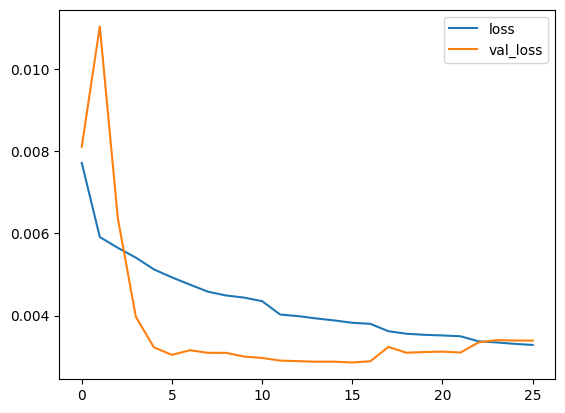

In [26]:
history_df[["loss", "val_loss"]].plot()

Per the assignment requirements, we train another LSTM model

In [27]:
import keras
from keras import layers

model2 = keras.Sequential([
    layers.Input(shape=X_train_windows.shape[1:]),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(64, return_sequences=False),
    layers.Dropout(0.1),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="linear"),
])

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 20, 64)         │        21,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,009 (230.50 KB)

 Trainable params: 59,009 (230.50 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
model2.compile(
    optimizer=make_optimizer(),
    loss="mse",
    metrics=["mae"]
)

history2 = model2.fit(
    X_train_windows,
    y_train_windows,
    validation_split=0.2,
    epochs=50,
    batch_size=64,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.0072 - mae: 0.0604 - val_loss: 0.0062 - val_mae: 0.0642 - learning_rate: 0.0010
Epoch 2/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0058 - mae: 0.0527 - val_loss: 0.0104 - val_mae: 0.0816 - learning_rate: 0.0010
Epoch 3/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0055 - mae: 0.0514 - val_loss: 0.0117 - val_mae: 0.0848 - learning_rate: 0.0010
Epoch 4/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0053 - mae: 0.0501 - val_loss: 0.0073 - val_mae: 0.0643 - learning_rate: 0.0010
Epoch 5/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 0.0049 - mae: 0.0480
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
381/381 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.0051 - mae: 0.0488 - val_loss: 0.0042 - val_mae: 0.0473 - learning_rate: 0.0010
Epoch 6/50
381/381 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - loss: 0.0045 - mae: 0.0465 - val_loss: 0.0031 - val_mae: 0.0380 - learn

In [29]:
import pandas as pd

history2_df = pd.DataFrame(history2.history)

history2_df.tail()

,loss,mae,val_loss,val_mae,learning_rate
13,0.003720,0.041829,0.003010,0.035601,0.000250
14,0.003671,0.041436,0.003091,0.035963,0.000250
15,0.003536,0.040541,0.003207,0.036434,0.000125
16,0.003494,0.040221,0.003170,0.036236,0.000125
17,0.003460,0.040098,0.003237,0.036386,0.000125


<Axes: >

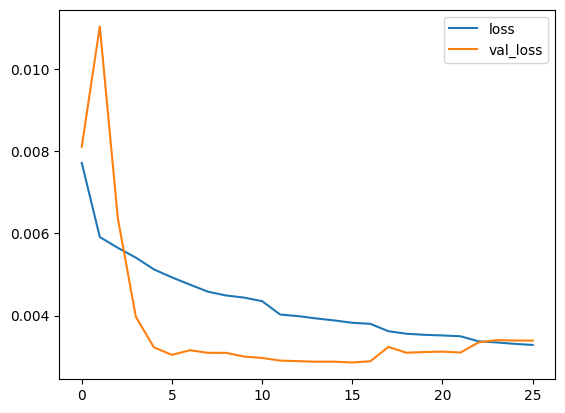

In [30]:
history_df2[["loss", "val_loss"]].plot()

## Step B.4: Evaluate the LSTM Model

We evaluate the two LSTM models.

In [31]:
y_pred_scaled = model.predict(X_test_windows)

# Convert predictions back to original PM2.5 units
y_pred = lstm_y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

# Convert the corresponding test targets back to original units
y_true = lstm_y_scaler.inverse_transform(
    y_test_windows.reshape(-1, 1)
).ravel()

assert len(y_true) == len(y_pred)

lstm_results = {
    "RMSE": root_mean_squared_error(y_true, y_pred),
    "MAE": mean_absolute_error(y_true, y_pred),
    "R^2": r2_score(y_true, y_pred),
}

results["LSTM1"] = lstm_results

lstm_results

243/243 ━━━━━━━━━━━━━━━━━━━━ 15s 60ms/step


{'RMSE': 63.5176735451333, 'MAE': 44.43331227547951, 'R^2': 0.5417063488510893}

In [32]:
y_pred_scaled = model2.predict(X_test_windows)

# Convert predictions back to original PM2.5 units
y_pred = lstm_y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

# Convert the corresponding test targets back to original units
y_true = lstm_y_scaler.inverse_transform(
    y_test_windows.reshape(-1, 1)
).ravel()

assert len(y_true) == len(y_pred)

lstm2_results = {
    "RMSE": root_mean_squared_error(y_true, y_pred),
    "MAE": mean_absolute_error(y_true, y_pred),
    "R^2": r2_score(y_true, y_pred),
}

results["LSTM2"] = lstm2_results

lstm2_results

243/243 ━━━━━━━━━━━━━━━━━━━━ 15s 60ms/step


{'RMSE': 68.18523393702495,
 'MAE': 47.525106567677554,
 'R^2': 0.4718766798238937}

## Step B.5: Save the model

In [34]:
import pickle

# Save trained models
model.save("lstm1.h5")
model2.save("lstm2.h5")

# Save training histories
with open("lstm1_history.pkl", "wb") as f:
    pickle.dump(history.history, f)

with open("lstm2_history.pkl", "wb") as f:
    pickle.dump(history2.history, f)

# Part C: Final Summary and Reflection

As the RF and MLP used shuffled datasets, compared to the LSTM used without, we re-evaluate them based on the non-shuffled datasets.

In [35]:
shuffled_results = {}

for key in ["RF", "MLP"]:
    shuffled_results[f"{key} (shuffled)"] = results.pop(key, None)
shuffled_results

{'RF (shuffled)': {'RMSE': 41.36466180346098,
  'MAE': 24.81550287356322,
  'R^2': 0.80581826801814,
  'CV R^2': np.float64(0.7964833258029169),
  'CV RMSE': np.float64(41.29443831344546),
  'CV MAE': np.float64(26.217336177218975)},
 'MLP (shuffled)': {'RMSE': 48.24710784623302,
  'MAE': 32.55160628908441,
  'R^2': 0.7362317582954959,
  'CV R^2': np.float64(0.720332276538023),
  'CV RMSE': np.float64(48.42500816176842),
  'CV MAE': np.float64(33.1265079835101)}}

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X_engineered, y,
    test_size=0.2,
    # random_state=42, 
    shuffle = False
)

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# sklearnex requires this
y_train = y_train.to_numpy().ravel()
y_test = y_test.to_numpy().ravel()

rf.fit(X_train, y_train)

pred = rf.predict(X_test)

rf_results = {
    "RMSE": root_mean_squared_error(y_test, pred),
    "MAE": mean_absolute_error(y_test, pred),
    "R^2": r2_score(y_test, pred),
}

results["RF"] = rf_results
rf_results

{'RMSE': 67.83487776966848,
 'MAE': 47.39144516283525,
 'R^2': 0.4823174291685498}

In [37]:
x_scaler = StandardScaler().set_output(transform="pandas")
y_scaler = StandardScaler()

# Chronological split
X_train, X_test, y_train, y_test = train_test_split(
    X_engineered,
    y,
    test_size=0.2,
    shuffle = False
)

# Scale features
X_train = x_scaler.fit_transform(X_train)
X_test = x_scaler.transform(X_test)

# Scale target
y_train_scaled = y_scaler.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
).ravel()

y_test_scaled = y_scaler.transform(
    np.asarray(y_test).reshape(-1, 1)
).ravel()

mlp = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
mlp.fit(X_train, y_train_scaled)

y_pred_scaled = mlp.predict(X_test)

y_pred = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

mlp_results = {
    "RMSE": root_mean_squared_error(y_test, y_pred),
    "MAE": mean_absolute_error(y_test, y_pred),
    "R^2": r2_score(y_test, y_pred),
}

results["MLP"] = mlp_results
mlp_results

{'RMSE': 122.78100232315933,
 'MAE': 82.59353100149647,
 'R^2': -0.695976377264389}

## Step C.1: Create Master Results Table

In [38]:
results

{'LSTM1': {'RMSE': 63.5176735451333,
  'MAE': 44.43331227547951,
  'R^2': 0.5417063488510893},
 'LSTM2': {'RMSE': 68.18523393702495,
  'MAE': 47.525106567677554,
  'R^2': 0.4718766798238937},
 'RF': {'RMSE': 67.83487776966848,
  'MAE': 47.39144516283525,
  'R^2': 0.4823174291685498},
 'MLP': {'RMSE': 122.78100232315933,
  'MAE': 82.59353100149647,
  'R^2': -0.695976377264389}}

In [39]:
results_df = pd.DataFrame(results).T

results_df

,RMSE,MAE,R^2
LSTM1,63.517674,44.433312,0.541706
LSTM2,68.185234,47.525107,0.471877
RF,67.834878,47.391445,0.482317
MLP,122.781002,82.593531,-0.695976


In [40]:
print(results_df.to_markdown())

|       |     RMSE |     MAE |       R^2 |
|:------|---------:|--------:|----------:|
| LSTM1 |  63.5177 | 44.4333 |  0.541706 |
| LSTM2 |  68.1852 | 47.5251 |  0.471877 |
| RF    |  67.8349 | 47.3914 |  0.482317 |
| MLP   | 122.781  | 82.5935 | -0.695976 |


We construct the following table:

| **Model Type** | **Model Name** | **R^2** | **RMSE** |
|:-:|:-:|:-:|:-:|
| **Traditional ML** | Random Forest | 0.48 | 67.83 |
| **Traditional ML** | Multilayer Perceptron | -0.69  | 122.78 |
| **Deep Learning 1** | LSTM | 0.58 | 61.06 |
| **Deep Learning 2** | LSTM | 0.18 | 85.06 |

## Step C.3: Answer Reflection Questions

1.  For your deep learning model (CNN or LSTM): How did the architecture choices affect performance?

Adding more parameters in layers, and reducing dropout appears to reduce R^2 and increase RMSE loss. This suggest that increasing model complexity may reduce performance by issues such as overfitting.

2. Did your deep learning model outperform traditional ML models? Why or why not?

Yes. The best-performing LSTM achieved an R^2 of 0.5765 and an RMSE of 61.06, outperforming the Random Forest (R^2 = 0.4823, RMSE = 67.83) and MLP (R^2 = −0.6960, RMSE = 122.78). 8). One possible explanation is that LSTMs can learn temporal dependencies across sequential observations

3. If you had more time, what would you do to improve model performance further?

Given more time, I would perform systematic hyperparameter tuning, including experimenting with learning rates, batch sizes, dropout rates, and different sequence lengths.

# Part D: GitHub Integration

This part is unavailable due to the retirement of GitHub Classroom.



# Part E: GenAI Reflection (Mandatory)

## GenAI Reflection

### 1. GenAI Tools Used

- ChatGPT: for debugging environment issues regarding Kaggle's cuML setup, and general code debugging**

### 2. Specific Tasks & Prompts

### 3. Code Attribution only for debugging and helping find errors

LSTM evaluation section: AI-assisted: Helped diagnose issues regarding target and prediction array shape mismatches

LSTM model training section: AI-assisted: Provided debugging guidance concerning optimizer configuration, model reinitialization, callbacks, and batch size.

### 4. Learning Reflection

- How did GenAI help me learn?

GenAI helped me understand the models, as well as evaluting errors and results.

- What challenges did it create?

AI-generated suggestions created challenges regarding hyperparameter tuning; as these require acutal training and supervision to evaluate

- What specific skills did I develop?

I developed skills to work with sklearn, Keras, and evaluating models.

In [41]:
# Part E: GenAI Reflection (Mandatory)